IMPORT LIBRARY

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


LOAD DATASET

In [27]:
# Membaca dataset
df = pd.read_csv("Dataset_Dummy_5000.csv")

print("--- 5 Data Pertama MPU6050 ---")
print(df.head())

--- 5 Data Pertama MPU6050 ---
   Percobaan  Percepatan dasar (g)  Percepatan struktur (g)  Perpindahan (mm)
0          1                  0.10                     0.15               0.8
1          2                  0.25                     0.40               2.4
2          3                  0.50                     0.75               4.7
3          4                  0.80                     1.10               6.2
4          5                  0.95                     1.35               7.5


In [ ]:
PENENTUAN KELAS DAN MEMISAH FITUR X(INPUT/SESOR) DAN Y(Rendah/Sedang,Tinggi)

In [28]:
def klasifikasi(displacement):
    if displacement <= 2.0:
        return "Rendah"
    elif displacement <= 5.0:
        return "Sedang"
    else:
        return "Tinggi"

# Menerapkan fungsi ke dataframe untuk membuat kolom kelas baru
df["kelas"] = df["Perpindahan (mm)"].apply(klasifikasi)

# 2.1 Menentukan Kolom Fitur (X) dan Target (y)
fitur = ["Percepatan dasar (g)", "Percepatan struktur (g)"]
X = df[fitur]
y = df["kelas"]

print("Preprocessing dan pelabelan selesai!")
display(df.tail(12)) # Menampilkan beberapa data terakhir beserta kelasnya

Preprocessing dan pelabelan selesai!


,Percobaan,Percepatan dasar (g),Percepatan struktur (g),Perpindahan (mm),kelas
4988,4989,0.08,0.16,1.07,Rendah
4989,4990,0.31,0.48,2.56,Sedang
4990,4991,0.19,0.25,1.74,Rendah
4991,4992,0.82,1.26,7.12,Tinggi
4992,4993,0.87,1.35,7.91,Tinggi
4993,4994,0.26,0.44,2.45,Sedang
4994,4995,0.85,1.19,7.01,Tinggi
4995,4996,0.51,0.72,4.36,Sedang
4996,4997,0.41,0.62,3.59,Sedang
4997,4998,0.64,0.91,6.09,Tinggi


In [ ]:
PEMBAGIAN DATA TRAINING DAN TEST

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Jumlah data latih: {len(X_train)}")
print(f"Jumlah data uji  : {len(X_test)}")

Jumlah data latih: 4000
Jumlah data uji  : 1000


In [ ]:
latih model decision tree

In [76]:

# Pelatihan Decision Tree dengan pohon lebih sederhana
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(
    max_depth=2,
    min_samples_leaf=100,
    random_state=42
)

model_dt.fit(X_train, y_train)

print("Model Decision Tree berhasil dilatih!")


Model Decision Tree berhasil dilatih!


PENGUJIAN MODEL DECISION TREE

In [68]:
pred_dt = model_dt.predict(X_test)

print("Pengujian model selesai!")
print("Jumlah data uji:", len(y_test))
print("Jumlah hasil prediksi:", len(pred_dt))


Pengujian model selesai!
Jumlah data uji: 1000
Jumlah hasil prediksi: 1000


In [ ]:
EVALUASI MODEL

In [69]:

# Menghitung metrik evaluasi
accuracy_dt = accuracy_score(y_test, pred_dt)

precision_dt = precision_score(
    y_test, pred_dt,
    average="weighted",
    zero_division=0
)

recall_dt = recall_score(
    y_test, pred_dt,
    average="weighted",
    zero_division=0
)

f1_dt = f1_score(
    y_test, pred_dt,
    average="weighted",
    zero_division=0
)

# Menampilkan hasil evaluasi
evaluasi = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Nilai (%)": [
        accuracy_dt * 100,
        precision_dt * 100,
        recall_dt * 100,
        f1_dt * 100
    ]
})

display(evaluasi.round(2))

print("\nClassification Report:")
print(classification_report(
    y_test,
    pred_dt,
    zero_division=0
))



,Metrik,Nilai (%)
0,Accuracy,93.80
1,Precision,93.81
2,Recall,93.80
3,F1-Score,93.79



Classification Report:
              precision    recall  f1-score   support

      Rendah       0.92      0.96      0.93       203
      Sedang       0.93      0.90      0.92       373
      Tinggi       0.96      0.96      0.96       424

    accuracy                           0.94      1000
   macro avg       0.93      0.94      0.94      1000
weighted avg       0.94      0.94      0.94      1000



Matriks

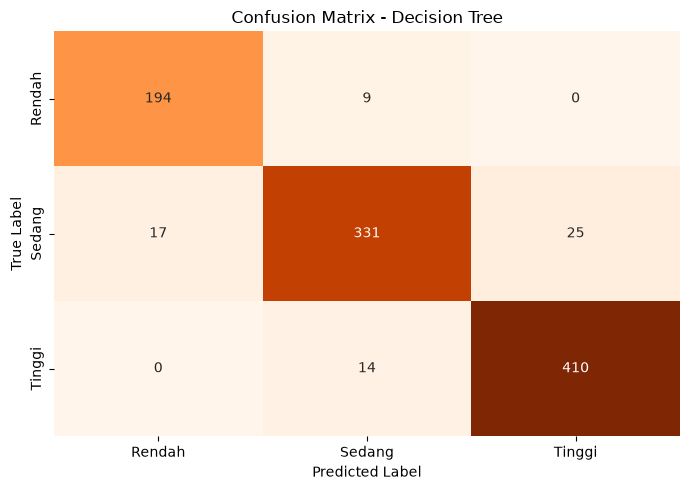

In [70]:

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    cbar=False,
    xticklabels=model_dt.classes_,
    yticklabels=model_dt.classes_
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


visualisasi pohon keputusan

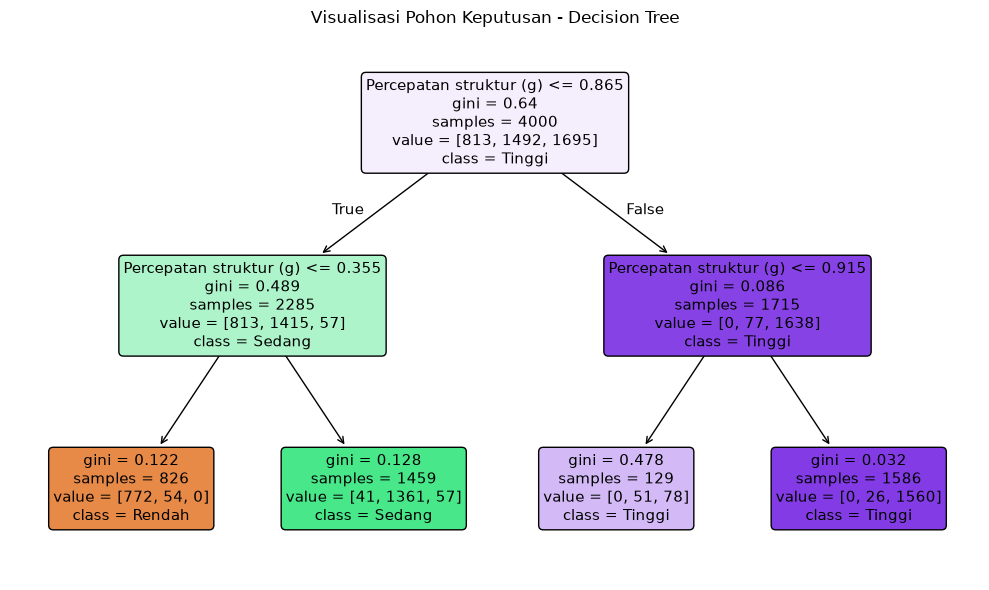

In [77]:
plt.figure(figsize=(10, 6))

plot_tree(
    model_dt,
   feature_names=X_train.columns.tolist(),
    class_names=model_dt.classes_.tolist(),
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False,
    precision=3,
    fontsize=11
)

plt.title("Visualisasi Pohon Keputusan - Decision Tree")
plt.tight_layout()
plt.show()


In [ ]:
MENGUJI DENGAN DATA BARU

In [54]:
# Input satu data baru
percepatan_dasar = 0.90
percepatan_struktur = 0.78

# Membentuk data sesuai nama fitur saat pelatihan
data_uji_baru = pd.DataFrame({
    "Percepatan dasar (g)": [percepatan_dasar],
    "Percepatan struktur (g)": [percepatan_struktur]
})

# Melakukan prediksi
hasil = model_dt.predict(data_uji_baru)

print("Percepatan dasar     :", percepatan_dasar, "g")
print("Percepatan struktur  :", percepatan_struktur, "g")
print("Prediksi kelas respons:", hasil[0])


Percepatan dasar     : 0.9 g
Percepatan struktur  : 0.78 g
Prediksi kelas respons: Sedang
